# Sales Data Analysis

## Cognetix Technology — Data Analyst Internship

### Project Objective

This project analyzes sales transaction data using Python and Pandas to identify key business trends and performance patterns.

The analysis focuses on:

- Overall sales performance
- Product-line performance
- Geographic sales distribution
- Top-performing products
- Monthly and yearly sales trends
- Deal-size distribution
- Order-status performance
- Business insights and recommendations

### Tools Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

In [45]:
import sys 
import pandas as pd 

print("Python:", sys.executable)
print("Pandas:", pd.__version__)

Python: c:\Users\tuntun'\AppData\Local\Programs\Python\Python312\python.exe
Pandas: 3.0.3


In [46]:
import pandas as pd

df = pd.read_csv("../data/sales_data_sample.csv", encoding="latin1")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [47]:
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [48]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 2823
Columns: 25


In [49]:
df.columns.tolist()

['ORDERNUMBER',
 'QUANTITYORDERED',
 'PRICEEACH',
 'ORDERLINENUMBER',
 'SALES',
 'ORDERDATE',
 'STATUS',
 'QTR_ID',
 'MONTH_ID',
 'YEAR_ID',
 'PRODUCTLINE',
 'MSRP',
 'PRODUCTCODE',
 'CUSTOMERNAME',
 'PHONE',
 'ADDRESSLINE1',
 'ADDRESSLINE2',
 'CITY',
 'STATE',
 'POSTALCODE',
 'COUNTRY',
 'TERRITORY',
 'CONTACTLASTNAME',
 'CONTACTFIRSTNAME',
 'DEALSIZE']

In [50]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 2823
Number of columns: 25


In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null    str    
 17  CITY  

In [52]:
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

ADDRESSLINE2    2521
STATE           1486
POSTALCODE        76
TERRITORY       1074
dtype: int64


In [53]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [54]:
df.describe()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP
count,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.00000,2823.000000
mean,10258.725115,35.092809,83.658544,6.466171,3553.889072,2.717676,7.092455,2003.81509,100.715551
std,92.085478,9.741443,20.174277,4.225841,1841.865106,1.203878,3.656633,0.69967,40.187912
min,10100.000000,6.000000,26.880000,1.000000,482.130000,1.000000,1.000000,2003.00000,33.000000
25%,10180.000000,27.000000,68.860000,3.000000,2203.430000,2.000000,4.000000,2003.00000,68.000000
50%,10262.000000,35.000000,95.700000,6.000000,3184.800000,3.000000,8.000000,2004.00000,99.000000
75%,10333.500000,43.000000,100.000000,9.000000,4508.000000,4.000000,11.000000,2004.00000,124.000000
max,10425.000000,97.000000,100.000000,18.000000,14082.800000,4.000000,12.000000,2005.00000,214.000000


In [55]:
print("Sales range:")
print("Minimum:", df["SALES"].min())
print("Maximum:", df["SALES"].max())

print("\nQuantity range:")
print("Minimum:", df["QUANTITYORDERED"].min())
print("Maximum:", df["QUANTITYORDERED"].max())

print("\nProduct lines:")
print(df["PRODUCTLINE"].unique())

print("\nRegions:")
print(df["COUNTRY"].nunique(), "unique countries")

Sales range:
Minimum: 482.13
Maximum: 14082.8

Quantity range:
Minimum: 6
Maximum: 97

Product lines:
<StringArray>
[     'Motorcycles',     'Classic Cars', 'Trucks and Buses',
     'Vintage Cars',           'Planes',            'Ships',
           'Trains']
Length: 7, dtype: str

Regions:
19 unique countries


In [56]:
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])

print(df["ORDERDATE"].dtype)

datetime64[us]


In [57]:
print("Negative sales:", (df["SALES"] < 0).sum())
print("Zero sales:", (df["SALES"] == 0).sum())

Negative sales: 0
Zero sales: 0


In [58]:
print("Negative quantities:", (df["QUANTITYORDERED"] < 0).sum())
print("Zero quantities:", (df["QUANTITYORDERED"] == 0).sum())

Negative quantities: 0
Zero quantities: 0


In [59]:
print("Product Lines:")
print(df["PRODUCTLINE"].unique())

Product Lines:
<StringArray>
[     'Motorcycles',     'Classic Cars', 'Trucks and Buses',
     'Vintage Cars',           'Planes',            'Ships',
           'Trains']
Length: 7, dtype: str


In [60]:
print("\nOrder Status:")
print(df["STATUS"].value_counts())


Order Status:
STATUS
Shipped       2617
Cancelled       60
Resolved        47
On Hold         44
In Process      41
Disputed        14
Name: count, dtype: int64


In [61]:
print("\nDeal Sizes:")
print(df["DEALSIZE"].value_counts())


Deal Sizes:
DEALSIZE
Medium    1384
Small     1282
Large      157
Name: count, dtype: int64


In [62]:
print("Number of countries:", df["COUNTRY"].nunique())
print("\nCountries:")
print(df["COUNTRY"].unique())

Number of countries: 19

Countries:
<StringArray>
[        'USA',      'France',      'Norway',   'Australia',     'Finland',
     'Austria',          'UK',       'Spain',      'Sweden',   'Singapore',
      'Canada',       'Japan',       'Italy',     'Denmark',     'Belgium',
 'Philippines',     'Germany', 'Switzerland',     'Ireland']
Length: 19, dtype: str


In [63]:
sales_df = df.copy()

print("Analysis dataset created.")
print("Rows:", sales_df.shape[0])
print("Columns:", sales_df.shape[1])

Analysis dataset created.
Rows: 2823
Columns: 25


In [64]:
sales_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ORDERNUMBER       2823 non-null   int64         
 1   QUANTITYORDERED   2823 non-null   int64         
 2   PRICEEACH         2823 non-null   float64       
 3   ORDERLINENUMBER   2823 non-null   int64         
 4   SALES             2823 non-null   float64       
 5   ORDERDATE         2823 non-null   datetime64[us]
 6   STATUS            2823 non-null   str           
 7   QTR_ID            2823 non-null   int64         
 8   MONTH_ID          2823 non-null   int64         
 9   YEAR_ID           2823 non-null   int64         
 10  PRODUCTLINE       2823 non-null   str           
 11  MSRP              2823 non-null   int64         
 12  PRODUCTCODE       2823 non-null   str           
 13  CUSTOMERNAME      2823 non-null   str           
 14  PHONE             2823 non-null   s

## Sales Performance Analysis

This section calculates the overall sales performance of the dataset using total, average, maximum, and minimum sales values.

In [65]:
total_sales = sales_df["SALES"].sum()
average_sales = sales_df["SALES"].mean()
maximum_sales = sales_df["SALES"].max()
minimum_sales = sales_df["SALES"].min()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Average Sales per Order Line: ${average_sales:,.2f}")
print(f"Maximum Sales: ${maximum_sales:,.2f}")
print(f"Minimum Sales: ${minimum_sales:,.2f}")

Total Sales: $10,032,628.85
Average Sales per Order Line: $3,553.89
Maximum Sales: $14,082.80
Minimum Sales: $482.13


In [66]:
sales_by_product = (
    sales_df.groupby("PRODUCTLINE")["SALES"]
    .sum()
    .sort_values(ascending=False)
)

print(sales_by_product)

PRODUCTLINE
Classic Cars        3919615.66
Vintage Cars        1903150.84
Motorcycles         1166388.34
Trucks and Buses    1127789.84
Planes               975003.57
Ships                714437.13
Trains               226243.47
Name: SALES, dtype: float64


In [67]:
product_sales_percentage = (
    sales_by_product / total_sales * 100
).round(2)

print(product_sales_percentage)

PRODUCTLINE
Classic Cars        39.07
Vintage Cars        18.97
Motorcycles         11.63
Trucks and Buses    11.24
Planes               9.72
Ships                7.12
Trains               2.26
Name: SALES, dtype: float64


In [68]:
sales_by_country = (
    sales_df.groupby("COUNTRY")["SALES"]
    .sum()
    .sort_values(ascending=False)
)

print(sales_by_country)

COUNTRY
USA            3627982.83
Spain          1215686.92
France         1110916.52
Australia       630623.10
UK              478880.46
Italy           374674.31
Finland         329581.91
Norway          307463.70
Singapore       288488.41
Denmark         245637.15
Canada          224078.56
Germany         220472.09
Sweden          210014.21
Austria         202062.53
Japan           188167.81
Switzerland     117713.56
Belgium         108412.62
Philippines      94015.73
Ireland          57756.43
Name: SALES, dtype: float64


In [69]:
top_10_countries = sales_by_country.head(10)

print(top_10_countries)

COUNTRY
USA          3627982.83
Spain        1215686.92
France       1110916.52
Australia     630623.10
UK            478880.46
Italy         374674.31
Finland       329581.91
Norway        307463.70
Singapore     288488.41
Denmark       245637.15
Name: SALES, dtype: float64


In [70]:
sales_by_product_code = (
    sales_df.groupby("PRODUCTCODE")["SALES"]
    .sum()
    .sort_values(ascending=False)
)

print(sales_by_product_code.head(10))

PRODUCTCODE
S18_3232    288245.42
S10_1949    191073.03
S10_4698    170401.07
S12_1108    168585.32
S18_2238    154623.95
S12_3891    145332.04
S24_3856    140626.90
S12_2823    140006.16
S18_1662    139421.97
S12_1099    137177.01
Name: SALES, dtype: float64


In [71]:
top_5_countries = sales_by_country.head(5)

print("Top 5 Countries by Sales:")
print(top_5_countries)

Top 5 Countries by Sales:
COUNTRY
USA          3627982.83
Spain        1215686.92
France       1110916.52
Australia     630623.10
UK            478880.46
Name: SALES, dtype: float64


In [72]:
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Average Sales per Order Line",
        "Maximum Sales",
        "Minimum Sales"
    ],
    "Value": [
        total_sales,
        average_sales,
        maximum_sales,
        minimum_sales
    ]
})

kpi_summary

,Metric,Value
0,Total Sales,1.003263e+07
1,Average Sales per Order Line,3.553889e+03
2,Maximum Sales,1.408280e+04
3,Minimum Sales,4.821300e+02


In [73]:
best_product_line = sales_by_product.idxmax()
best_product_sales = sales_by_product.max()

worst_product_line = sales_by_product.idxmin()
worst_product_sales = sales_by_product.min()

print(f"Best-performing product line: {best_product_line}")
print(f"Sales: ${best_product_sales:,.2f}")

print(f"\nLowest-performing product line: {worst_product_line}")
print(f"Sales: ${worst_product_sales:,.2f}")

Best-performing product line: Classic Cars
Sales: $3,919,615.66

Lowest-performing product line: Trains
Sales: $226,243.47


In [74]:
classic_cars_share = (
    sales_by_product["Classic Cars"] / total_sales
) * 100

print(f"Classic Cars contribution: {classic_cars_share:.2f}%")

Classic Cars contribution: 39.07%


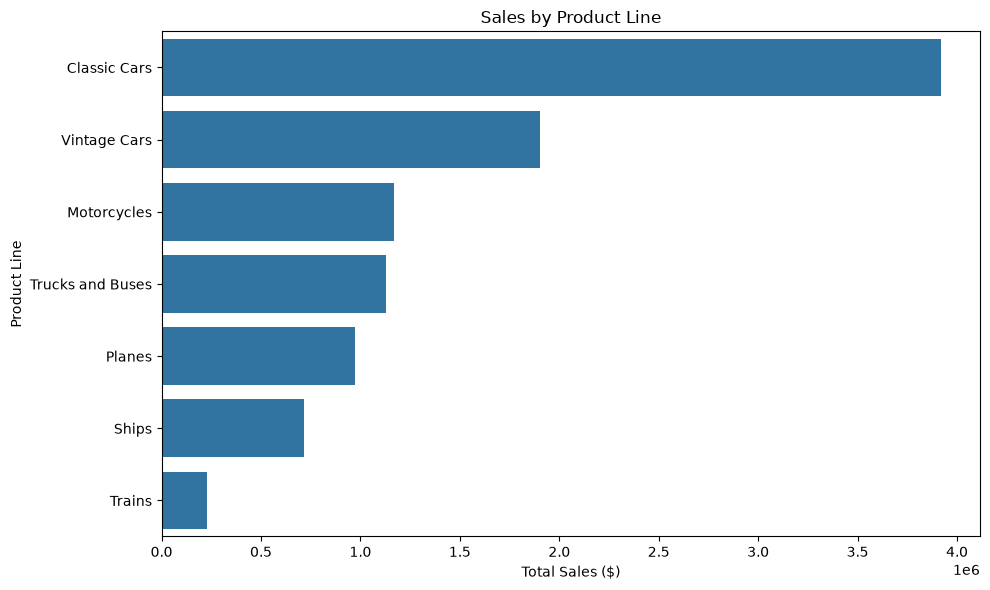

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    x=sales_by_product.values,
    y=sales_by_product.index
)

plt.title("Sales by Product Line")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product Line")
plt.tight_layout()

plt.show()

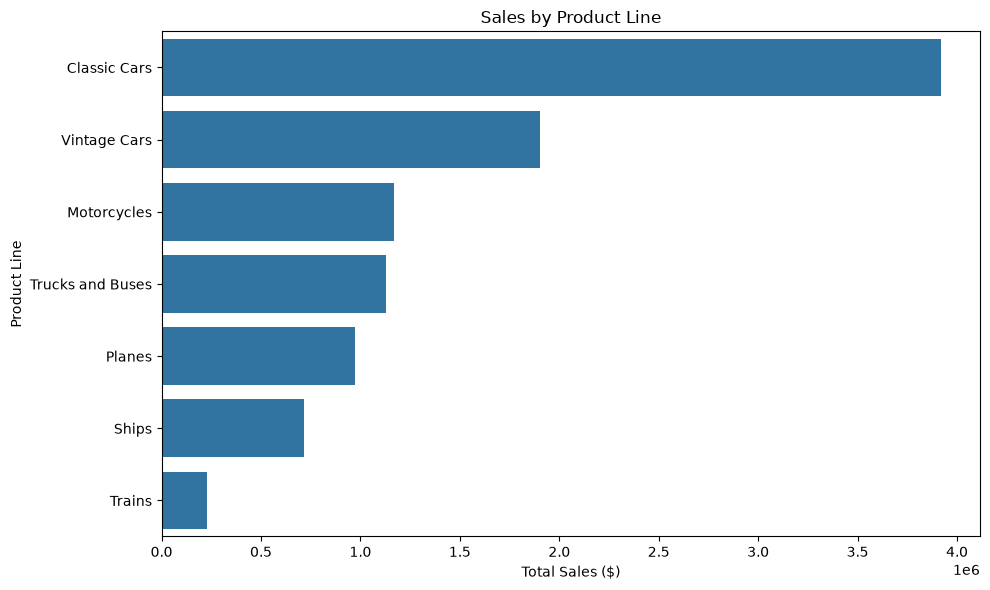

In [76]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=sales_by_product.values,
    y=sales_by_product.index
)

plt.title("Sales by Product Line")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product Line")
plt.tight_layout()

plt.savefig("../visuals/sales_by_product_line.png", dpi=300, bbox_inches="tight")
plt.show()

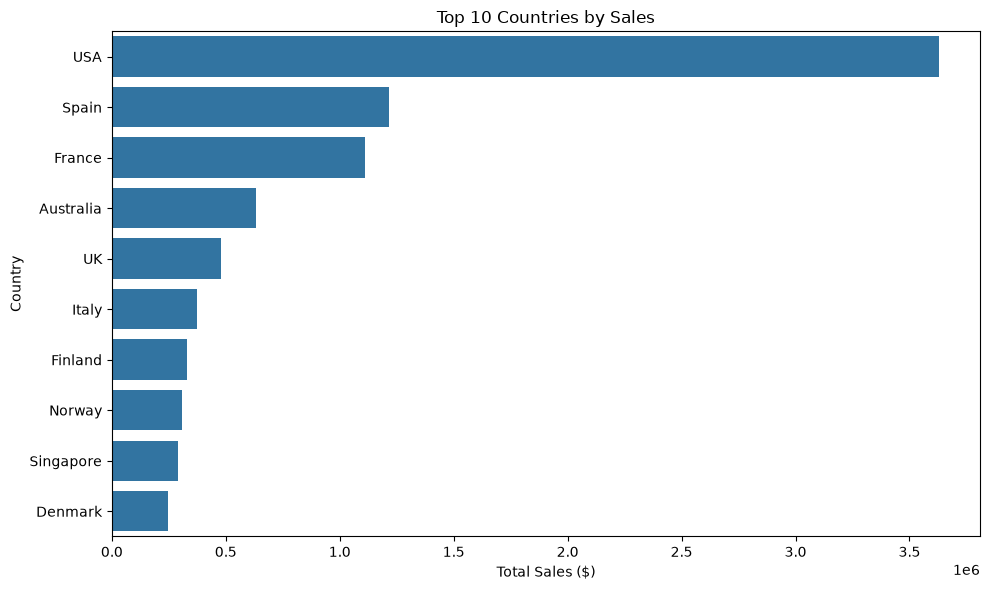

In [77]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index
)

plt.title("Top 10 Countries by Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig("../visuals/top_10_countries.png", dpi=300, bbox_inches="tight")
plt.show()

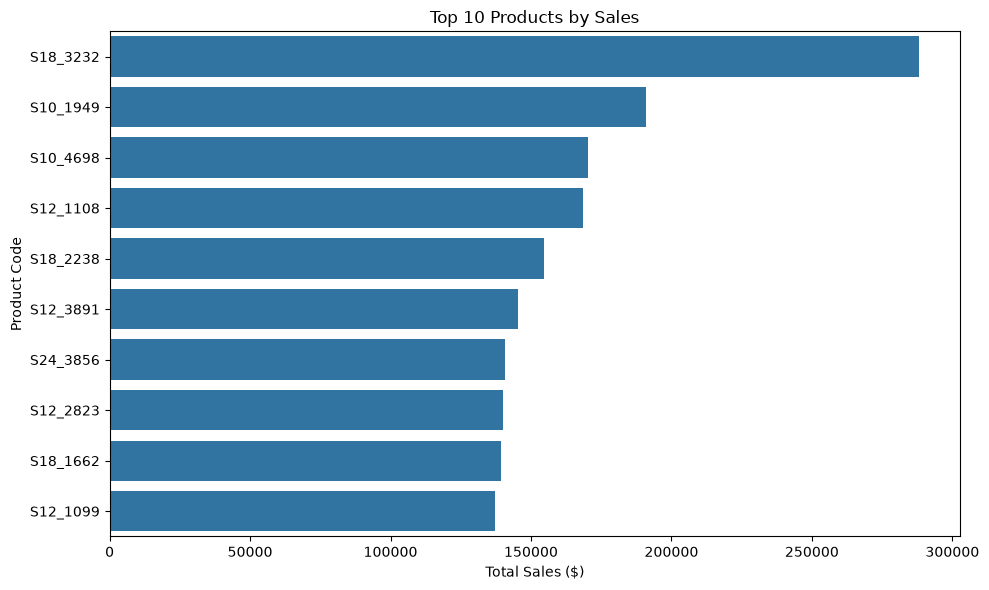

In [78]:
top_10_products = sales_by_product_code.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_products.values,
    y=top_10_products.index
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product Code")
plt.tight_layout()

plt.savefig(
    "../visuals/top_10_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [79]:
monthly_sales = (
    sales_df.groupby(["YEAR_ID", "MONTH_ID"])["SALES"]
    .sum()
    .reset_index()
)

monthly_sales["PERIOD"] = (
    monthly_sales["YEAR_ID"].astype(str)
    + "-"
    + monthly_sales["MONTH_ID"].astype(str).str.zfill(2)
)

monthly_sales.head()

,YEAR_ID,MONTH_ID,SALES,PERIOD
0,2003,1,129753.60,2003-01
1,2003,2,140836.19,2003-02
2,2003,3,174504.90,2003-03
3,2003,4,201609.55,2003-04
4,2003,5,192673.11,2003-05


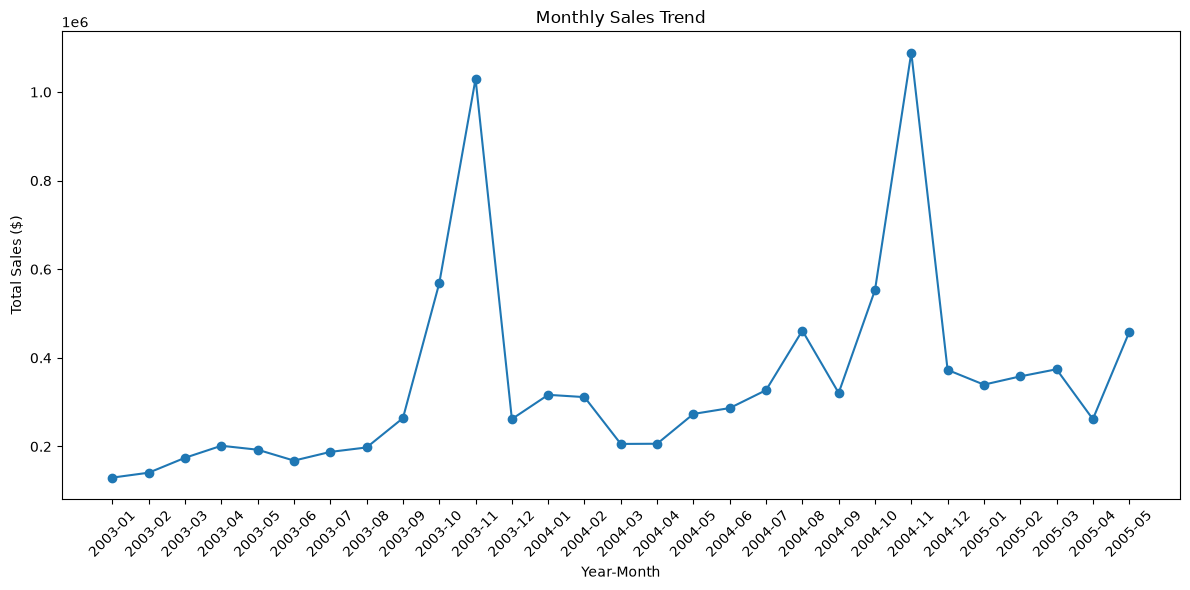

In [80]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["PERIOD"],
    monthly_sales["SALES"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../visuals/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [81]:
yearly_sales = (
    sales_df.groupby("YEAR_ID")["SALES"]
    .sum()
    .sort_index()
)

yearly_sales

YEAR_ID
2003    3516979.54
2004    4724162.60
2005    1791486.71
Name: SALES, dtype: float64

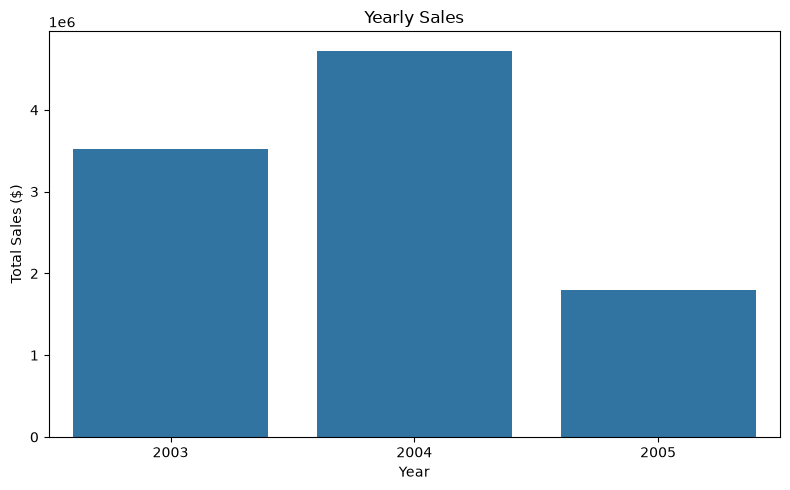

In [82]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=yearly_sales.index.astype(str),
    y=yearly_sales.values
)

plt.title("Yearly Sales")
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.tight_layout()

plt.savefig(
    "../visuals/yearly_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [83]:
deal_size_counts = sales_df["DEALSIZE"].value_counts()

deal_size_counts

DEALSIZE
Medium    1384
Small     1282
Large      157
Name: count, dtype: int64

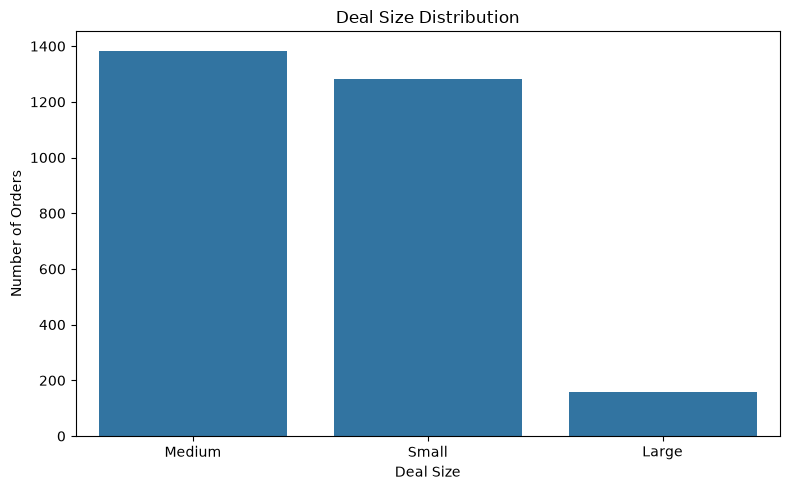

In [84]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=deal_size_counts.index,
    y=deal_size_counts.values
)

plt.title("Deal Size Distribution")
plt.xlabel("Deal Size")
plt.ylabel("Number of Orders")
plt.tight_layout()

plt.savefig(
    "../visuals/deal_size_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [85]:
sales_by_status = (
    sales_df.groupby("STATUS")["SALES"]
    .sum()
    .sort_values(ascending=False)
)

sales_by_status

STATUS
Shipped       9291501.08
Cancelled      194487.48
On Hold        178979.19
Resolved       150718.28
In Process     144729.96
Disputed        72212.86
Name: SALES, dtype: float64

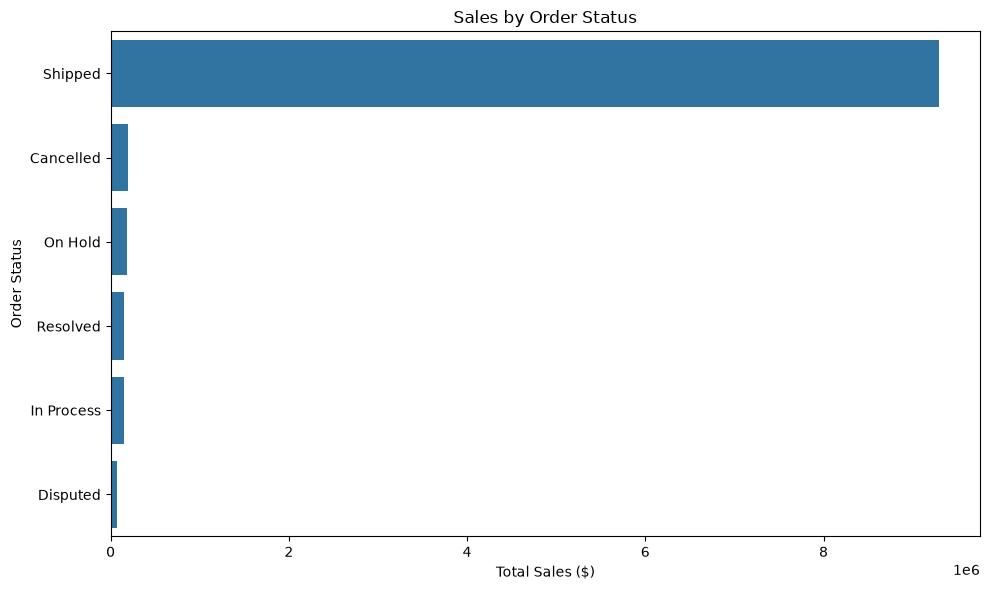

In [86]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=sales_by_status.values,
    y=sales_by_status.index
)

plt.title("Sales by Order Status")
plt.xlabel("Total Sales ($)")
plt.ylabel("Order Status")
plt.tight_layout()

plt.savefig(
    "../visuals/sales_by_order_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [87]:
# Final Business Analysis

# 1. Best and worst product lines
best_product_line = sales_by_product.idxmax()
best_product_sales = sales_by_product.max()

worst_product_line = sales_by_product.idxmin()
worst_product_sales = sales_by_product.min()

# 2. Best-performing country
best_country = sales_by_country.idxmax()
best_country_sales = sales_by_country.max()
best_country_share = (best_country_sales / total_sales) * 100

# 3. Best-selling product
best_product = sales_by_product_code.idxmax()
best_product_code_sales = sales_by_product_code.max()

# 4. Peak sales month
peak_month = monthly_sales.loc[
    monthly_sales["SALES"].idxmax()
]

# 5. Best sales year
best_year = yearly_sales.idxmax()
best_year_sales = yearly_sales.max()

# 6. Most common deal size
most_common_deal_size = deal_size_counts.idxmax()
most_common_deal_count = deal_size_counts.max()

# 7. Sales by order status
top_status = sales_by_status.idxmax()
top_status_sales = sales_by_status.max()

print("===== KEY BUSINESS INSIGHTS =====")

print(
    f"Best Product Line: {best_product_line} "
    f"(${best_product_sales:,.2f})"
)

print(
    f"Worst Product Line: {worst_product_line} "
    f"(${worst_product_sales:,.2f})"
)

print(
    f"Top Country: {best_country} "
    f"(${best_country_sales:,.2f}, {best_country_share:.2f}% of total sales)"
)

print(
    f"Top Product: {best_product} "
    f"(${best_product_code_sales:,.2f})"
)

print(
    f"Peak Sales Month: {peak_month['PERIOD']} "
    f"(${peak_month['SALES']:,.2f})"
)

print(
    f"Best Sales Year: {best_year} "
    f"(${best_year_sales:,.2f})"
)

print(
    f"Most Common Deal Size: {most_common_deal_size} "
    f"({most_common_deal_count:,} orders)"
)

print(
    f"Highest-Sales Order Status: {top_status} "
    f"(${top_status_sales:,.2f})"
)

===== KEY BUSINESS INSIGHTS =====
Best Product Line: Classic Cars ($3,919,615.66)
Worst Product Line: Trains ($226,243.47)
Top Country: USA ($3,627,982.83, 36.16% of total sales)
Top Product: S18_3232 ($288,245.42)
Peak Sales Month: 2004-11 ($1,089,048.01)
Best Sales Year: 2004 ($4,724,162.60)
Most Common Deal Size: Medium (1,384 orders)
Highest-Sales Order Status: Shipped ($9,291,501.08)


 Business Insights

1. **Product Performance:** Classic Cars are the strongest-performing product line, generating **$3.92 million**, or approximately **39.07% of total sales**. Trains are the lowest-performing product line at **$226.24K**.

2. **Geographic Performance:** The **USA** is the largest market, generating **$3.63 million**, which represents approximately **36.16% of total sales**. Spain and France are the next strongest markets.

3. **Product Performance:** Product **S18_3232** is the highest-selling individual product code, generating approximately **$288.25K** in sales.

4. **Seasonal Performance:** The highest monthly sales occurred in **November 2004**, reaching approximately **$1.09 million**. The monthly trend also shows strong sales peaks toward the end of the year.

5. **Yearly Performance:** **2004** was the strongest year in the dataset, generating approximately **$4.72 million** in sales. The 2005 figure should not be treated as a full-year comparison because the dataset only contains data through May 2005.

6. **Deal Size:** Medium-sized deals are the most common, accounting for **1,384 orders**, followed by small deals with 1,282 orders. Large deals are comparatively less frequent.

7. **Order Status:** Shipped orders account for approximately **$9.29 million** in sales, indicating that the majority of sales value is associated with successfully shipped orders.

Recommendations

1. **Strengthen the Classic Cars category:** Since Classic Cars generate the largest share of revenue, maintaining product availability and targeted promotions in this category could help sustain its strong performance.

2. **Focus on high-performing markets:** The USA contributes the largest share of sales. Similar strategies could be evaluated for other strong markets such as Spain and France to support further growth.

3. **Investigate low-performing product lines:** Trains generate substantially lower sales than the other product lines. Their pricing, demand, product positioning, and marketing performance should be reviewed before allocating additional resources.

4. **Plan around seasonal demand:** The strong sales peaks observed toward the end of the year suggest that inventory and marketing activities should be planned in advance of these periods.

5. **Increase high-value transactions:** Since medium and small deals dominate the order distribution, targeted bundles, cross-selling, and promotional strategies could be explored to encourage larger transactions.

6. **Monitor order-status performance:** Since shipped orders represent the majority of sales value, continued monitoring of cancellations, disputes, and orders on hold can help identify potential operational issues.